# Cross integration: Multiple RNA + ADT + ATAC

Cross integration combines batches that all measure the same modalities. The task is to remove batch effects and keep the biological structure. This tutorial is for batches that each hold RNA, ADT and ATAC peaks. It runs StabMap and UINMF on `D59mini`, 3,000 cells in two batches of the benchmark dataset `D59`, and then on data in your own format.

Methods run on Linux. On macOS or Windows, [open this notebook in Colab](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_cross_rna_adt_atac.ipynb).

## 1. Install

This cell installs `multibench-sc`. It keeps the numpy and pandas that are already installed, so Colab needs no restart.

<details>
<summary>Details</summary>

On Colab, choose a GPU runtime before you run the notebook: Runtime -> Change runtime type -> T4 GPU. On a CPU runtime, an environment that has a smaller CPU build gets that build, and training methods run slower.

</details>

In [1]:
import numpy, pandas
pins = f"numpy=={numpy.__version__} pandas=={pandas.__version__}"
%pip install -q "multibench-sc>=0.3.8" {pins}

Note: you may need to restart the kernel to use updated packages.


## 2. Download the data and the environments

`mtb.data.fetch` downloads `D59mini` (8 MB) once. Each method runs in its own environment. `mtb.env.install` downloads the environments for StabMap and UINMF, with no conda needed. The download is 0.9 GB.

<details>
<summary>Details</summary>

`state` is `PACKED` for an environment downloaded now and `have` for one that was already there. Without `dry_run=False`, `mtb.env.install` downloads nothing and returns the plan with its sizes.

Environments go to `mtb.config.DEFAULT.envs_dir`. To use another disk, set it before this cell.

From a terminal, `multibench env install --methods StabMap,UINMF --packed --run` does the same.

</details>

In [2]:
import pandas as pd
import multibench as mtb

mtb.data.fetch("D59mini")

downloading D59mini (8 MB) from https://github.com/DSichang/scMultiBench/releases/download/data-v1/D59mini.tar.gz ...


PosixPath('/tmp/mbtut_cls2/home/.cache/multibench/data')

In [3]:
METHODS = ["StabMap", "UINMF"]
envs = mtb.env.install(METHODS, dry_run=False)
pd.DataFrame(envs)[["env", "methods", "state"]]

[env] downloading scmb_r (single build) 917 MB ...


[env]   92 MB of 917 MB (62 MB/s)


[env]   184 MB of 917 MB (68 MB/s)


[env]   276 MB of 917 MB (69 MB/s)


[env]   367 MB of 917 MB (71 MB/s)


...

[env]   734 MB of 917 MB (74 MB/s)


[env]   826 MB of 917 MB (73 MB/s)


[env]   917 MB of 917 MB (73 MB/s)


[env] unpacking scmb_r -> /tmp/mbtut_cls2/home/.cache/multibench/envs/scmb_r ...


,env,methods,state
0,scmb_r,"[StabMap, UINMF]",PACKED


## 3. Run the methods

`run_all` runs each method on `D59mini` and scores its output with the scIB metrics and the classification scores (OCA, ACA, Spec, Sens, F1). `res.summary` has one row per method with its status, run time and scores. Higher is better for every metric.

<details>
<summary>Details</summary>

Each method writes an embedding: a table of numbers with one row per cell. `run_all` scores it against the cell-type labels of `D59mini`.

The clustering metrics `ARI`, `NMI`, `ASW`, `iASW`, `iF1` and `cLISI` measure how well the embedding separates the cell types. The batch metrics `ASW_batch`, `GC` and `iLISI` measure how well the batches mix. They appear only when the data has several batches.

`res.failures` says why a method failed. `params={"Method": {"key": value}}` sets a method's parameters, and `mtb.params_for` lists them. Many methods take none.

`mtb.load_batch("out/D59mini")` reloads these results later without running anything.

</details>

In [4]:
res = mtb.run_all("D59mini", "cross", methods=METHODS,
                  out_dir="out/D59mini")
res.summary

[run_all] StabMap runs on rna1+rna2+adt1+adt2+atac1+atac2, not on adt1+adt2+atac1+atac2, whose files are part of it. Pass modalities= to run a smaller combination.


[run_all] UINMF runs on rna1+rna2+adt1+adt2+atac1+atac2, not on rna1+rna2+adt1+adt2, rna1+rna2+atac1+atac2 and adt1+adt2+atac1+atac2, whose files are part of it. Pass modalities= to run a smaller combination.


[run_all] 4 more rows need files this folder does not have. mtb.scan shows them.


[run_all] StabMap (cross/D59mini) ...


Fetching the method scripts from PYangLab/scMultiBench into /tmp/mbtut_cls2/home/.cache/multibench/scMultiBench_ref ...


[run_all]   -> CHAIN_OK (19.2s) ARI 0.443


[run_all] UINMF (cross/D59mini) ...


[run_all]   -> CHAIN_OK (19.2s) ARI 0.661


,method,status,run_sec,output_kind,emb_shape,n_tunable,label_order,label_order_confidence,batch_source,n_batches,...,GC,iLISI,OCA,ACA,Spec,Sens,F1,label_order_note,caveat,reason
0,StabMap,CHAIN_OK,19.2,embedding,"[3000, 50]",0,cty2.csv+cty1.csv,0.9959,file_of_origin,2,...,0.7962,0.7580,0.6924,0.5477,0.9788,0.5477,0.4655,None,,
1,UINMF,CHAIN_OK,19.2,embedding,"[3000, 30]",0,cty1.csv+cty2.csv,0.9968,file_of_origin,2,...,0.7967,0.7797,0.7787,0.5248,0.9818,0.5248,0.4733,None,,


## 4. Plot

`res.plot()` draws the scores as a bubble table. Circle size shows the rank within a column, and bigger is better. The fill compares a value with the other rows in the same column.

<details>
<summary>Details</summary>

The lightest fill is the lowest value in this figure, not zero.

Metrics are grouped by family: blue for dimension reduction and clustering, green for batch correction, pink for classification. Each family starts with an `Overall` bar. Its length and colour both show the family score.

A column whose rows all hold the same value is drawn grey, and a warning names it. A figure of one method is grey everywhere.

</details>

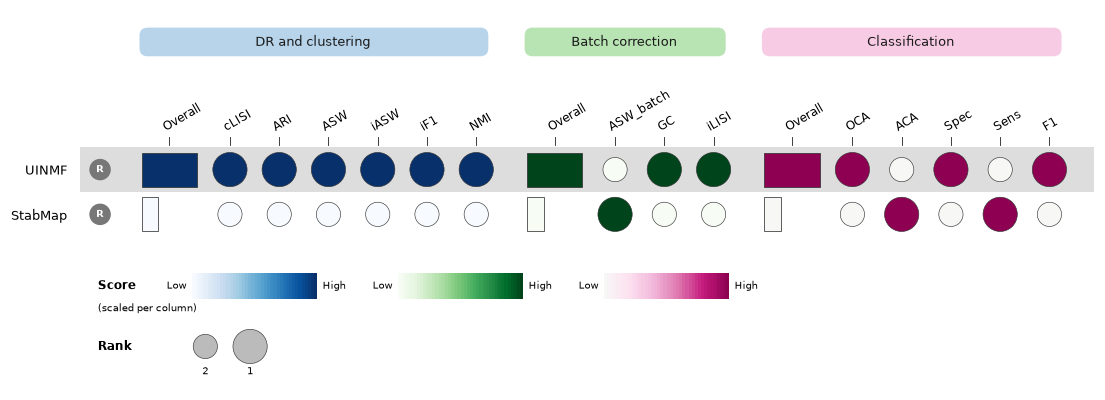

In [5]:
res.plot()

## 5. Your own data

Your data needs raw RNA and ADT counts in one `.h5ad` file and an ATAC peak matrix of the same cells in another, with a cell type and a batch for each cell. ADT means the protein counts. A batch is a donor, a sample or an experiment. `mtb.io.export_dataset` with `batch=` writes one set of files per batch.

The methods of this task read two batches. The recipe for another number of donors covers the other cases.

Starting from something else? See the recipes for [a 10x `.h5` file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-10x-h5), [labels in a CSV file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-labels-csv), [no labels](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-no-labels) and [another number of donors](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-donors).

<details>
<summary>Details: export</summary>

The names in quotes say where your file holds each part. `"X"` is the main matrix, `"obsm:protein"` the matrix `obsm["protein"]`, `"layer:counts"` the layer `layers["counts"]`, and `"obs:celltype"` the column `obs["celltype"]`, which `"celltype"` alone names too. A wrong name after `obsm:`, `layer:` or `obs:` raises an error that lists the names the file has.

The example keeps the protein names in `adata.uns["protein_names"]`. A DataFrame in `adata.obsm["protein"]` brings its own names in its columns.

The batches are numbered in the sorted order of their names, read as text: donors `A`, `B` and `C` become batches 1, 2 and 3, and `10` comes before `2`.

For one AnnData per batch, call `export_dataset` once per batch with `batch_index=N` instead of `batch=`, and pass `n_batches=` with the number of batches in every call.

`NAME` is the dataset name for `scan` and `run_all`, and `mydata` is the folder that holds it (`data_path`). With a new value of `NAME`, the folder holds the files of your data only.

The check lists the methods you name. Without `methods=`, it lists every method that reads the modalities in the folder. Without `per_method=True`, it has one row per method variant and every column, such as the command of each method.

`export_dataset` raises `FileExistsError` when the folder holds files of other cells that the call does not write. `overwrite=True` does not remove them. Give `NAME` a new value. After `batch=`, the files of batch numbers that the call does not write count as well.

`overwrite=True` replaces the files of an earlier run of this cell. Without it, `export_dataset` raises `FileExistsError` rather than replace a file.

</details>

The cells below read your data, write it as a dataset folder, check the folder and run the same methods on it. So that the notebook runs as it is, the next cell writes two small example files, `my_file.h5ad` and `my_atac.h5ad`, from 60% of the cells of `D59mini`, with a batch column. It leaves a file of your own with one of those names as it is.

In [6]:
mtb.data.write_example("D59mini")

wrote my_file.h5ad: 1,800 cells. RNA counts in X, protein counts in obsm["protein"], cell types in obs["celltype"], batches in obs["batch"].


wrote my_atac.h5ad: 1,800 cells. ATAC peak counts in X, cell types in obs["celltype"], batches in obs["batch"].


Read your files. For your own data, change every file name marked `# <-`. A name that you leave is read from the example. On Colab, upload the files first: click the folder icon on the left, then the upload icon. The cell reads `.h5ad` files. A 10x `.h5` file is read another way: see the recipe for a 10x `.h5` file, linked at the top of this section.

In [7]:
import anndata as ad

adata = ad.read_h5ad("my_file.h5ad")   # <- your RNA and protein file
atac = ad.read_h5ad("my_atac.h5ad")    # <- your peak file, the same cells
print(adata)
print(atac)

AnnData object with n_obs × n_vars = 1800 × 1000
    obs: 'celltype', 'batch'
    uns: 'protein_names'
    obsm: 'protein'
AnnData object with n_obs × n_vars = 1800 × 5000
    obs: 'celltype', 'batch'


Write the dataset folder. Change each name in quotes marked `# <-`: give `NAME` a new value, and write the names that your files use for the other parts. The printout above lists the names in your files. Write a name listed after `obs:` with that prefix, as `"obs:celltype"`, and one after `obsm:` as `"obsm:protein"`. When the folder holds batches that your data does not have, `export_dataset` stops and names the files. A new value of `NAME` avoids that.

In [8]:
NAME = "MYCROSS_TRI"   # <- a new name for your own data
mtb.io.export_dataset(adata, "mydata/" + NAME,
                      rna="X",                # <- where the RNA counts are
                      adt="obsm:protein",     # <- where the proteins (ADT) are
                      atac=atac,              # the ATAC file, peak counts in X
                      atac_kind="peak",       # the methods here read peaks
                      labels="obs:celltype",  # <- the cell-type column
                      batch="obs:batch",      # <- the batch or donor column
                      category="cross", overwrite=True)

PosixPath('mydata/MYCROSS_TRI')

Check the folder before you run anything. `runnable` says whether a method can run on your data on this computer, and `reason` says why not. The first two lines above the table say what the folder holds and how many cells each file has. Compare them with your data. A further line is about one method: why it cannot run, or what it does not read or needs from your data. With fewer batches than the methods read, such a line names the files that are not there. With more, it says which batches are not used.

In [9]:
mtb.scan(NAME, "cross", methods=METHODS, data_path="mydata",
         per_method=True)

[scan] 2 of 2 methods have their input files in MYCROSS_TRI. 2 of 2 can run on this computer. MYCROSS_TRI holds RNA, ADT and ATAC, in batches 1-2.


[scan] Cells per file: rna1.h5 913, adt1.h5 913, atac_peak1.h5 913, rna2.h5 887, adt2.h5 887, atac_peak2.h5 887.


,method,runnable,reason
0,StabMap,True,
1,UINMF,True,


Run the same methods on the folder:

In [10]:
mine = mtb.run_all(NAME, "cross", methods=METHODS, data_path="mydata",
                   out_dir="out/" + NAME)
mine.summary

[run_all] StabMap runs on rna1+rna2+adt1+adt2+atac1+atac2, not on adt1+adt2+atac1+atac2, whose files are part of it. Pass modalities= to run a smaller combination.


[run_all] UINMF runs on rna1+rna2+adt1+adt2+atac1+atac2, not on rna1+rna2+adt1+adt2, rna1+rna2+atac1+atac2 and adt1+adt2+atac1+atac2, whose files are part of it. Pass modalities= to run a smaller combination.


[run_all] 4 more rows need files this folder does not have. mtb.scan shows them.


[run_all] StabMap (cross/MYCROSS_TRI) ...


[run_all]   -> CHAIN_OK (11.1s) ARI 0.446


[run_all] UINMF (cross/MYCROSS_TRI) ...


[run_all]   -> CHAIN_OK (17.4s) ARI 0.451


,method,status,run_sec,output_kind,emb_shape,n_tunable,label_order,label_order_confidence,batch_source,n_batches,...,GC,iLISI,OCA,ACA,Spec,Sens,F1,label_order_note,caveat,reason
0,StabMap,CHAIN_OK,11.1,embedding,"[1800, 50]",0,cty2.csv+cty1.csv,0.9951,file_of_origin,2,...,0.8062,0.8199,0.6825,0.4812,0.9777,0.4812,0.4073,None,,
1,UINMF,CHAIN_OK,17.4,embedding,"[1800, 30]",0,cty1.csv+cty2.csv,0.9982,file_of_origin,2,...,0.8440,0.5599,0.5760,0.3229,0.9646,0.3229,0.3020,None,,


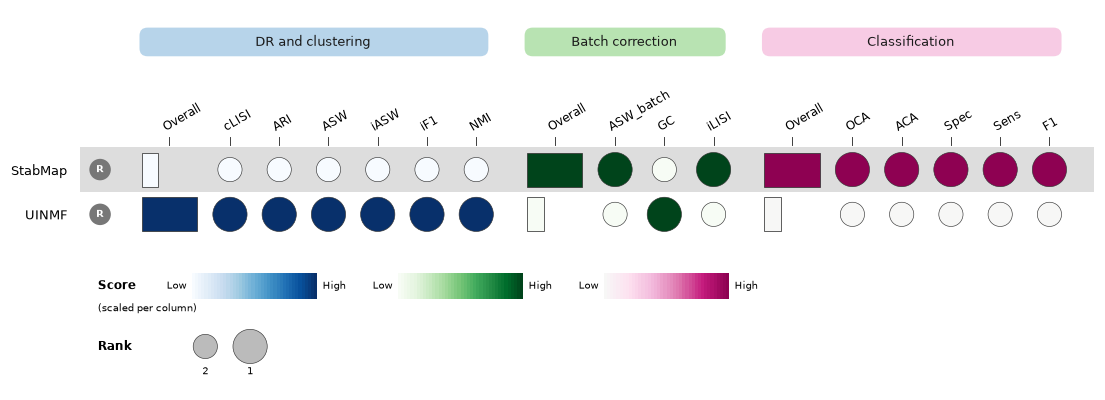

In [11]:
mine.plot()

## 6. Every method of this task

5 methods have a variant for cross Multiple RNA + ADT + ATAC. Each ran on `D59mini` in the package's own check, on a server with a GPU:

| Method | Result | Seconds |
|---|---|---|
| MOFA2 | scored | 42 |
| Multigrate | scored | 43 |
| StabMap | scored | 13 |
| UINMF | scored | 26 |
| scMoMaT | scored on the UMAP it writes | 113 |

To run them all, set `METHODS` to these names in section 2 and run the notebook again. That downloads 4 envs, 15.8 GB to download on a CPU host, 15.5 GB on a GPU host. [This notebook](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_cross_rna_adt_atac_all.ipynb) does the same in Colab.

## Troubleshooting

`res.failures` lists each method that failed or was skipped. Its `error` column ends with the method's error output.

<details>
<summary>Details</summary>

| symptom | fix |
|---|---|
| `env.install` refuses on macOS or Windows | methods run only on Linux: use Colab or a Linux machine |
| a method needs an NVIDIA GPU | choose a GPU runtime on Colab, or a machine with a GPU |
| a method fails on a small dataset | `mtb.scan` without `per_method=True` names what the method needs from the data's size in its `caveat` column |
| a warning that values are not whole numbers | export raw counts, for example with `rna="layer:counts"` |
| `... matrix/data as cells x features` | the matrix is transposed: export it again with `mtb.io.export_dataset` |
| a method times out | raise `timeout=` in `run_all` |
| low `label_order_confidence` | several label files fit the cell count: check `label_order_candidates` in `res.results` |
| batch metrics use the wrong batches | `res.rescore(batch=my_vector)` scores again without running the methods |

</details>

## Next steps

- `mtb.cite(METHODS)` returns the citations for the benchmark and the methods you ran.
- The other tutorials: [vertical RNA + ADT](https://dsichang.github.io/scMultiBench/tutorials/vertical_rna_adt/), [vertical RNA + ATAC](https://dsichang.github.io/scMultiBench/tutorials/vertical_rna_atac/), [vertical RNA + ADT + ATAC](https://dsichang.github.io/scMultiBench/tutorials/vertical_rna_adt_atac/), [diagonal [RNA, ATAC]](https://dsichang.github.io/scMultiBench/tutorials/diagonal_rna_atac/), [diagonal [multiple RNA, multiple ATAC]](https://dsichang.github.io/scMultiBench/tutorials/diagonal_multi/), [mosaic [RNA, RNA + ADT, ADT]](https://dsichang.github.io/scMultiBench/tutorials/mosaic_rna_adt/), [mosaic [RNA, RNA + ATAC, ATAC]](https://dsichang.github.io/scMultiBench/tutorials/mosaic_rna_atac/), [mosaic Mixed, with shared modality](https://dsichang.github.io/scMultiBench/tutorials/mosaic_shared/), [mosaic Mixed, without shared modality](https://dsichang.github.io/scMultiBench/tutorials/mosaic_unshared/), [cross Multiple RNA + ADT](https://dsichang.github.io/scMultiBench/tutorials/cross_rna_adt/), [cross Multiple RNA + ATAC](https://dsichang.github.io/scMultiBench/tutorials/cross_rna_atac/), [cross Multiple ADT + ATAC](https://dsichang.github.io/scMultiBench/tutorials/cross_adt_atac/).
- The guides: [run](https://dsichang.github.io/scMultiBench/tutorials/run/), [evaluate](https://dsichang.github.io/scMultiBench/tutorials/evaluate/), [plot](https://dsichang.github.io/scMultiBench/tutorials/plot/) and [discover methods](https://dsichang.github.io/scMultiBench/tutorials/discover/).
- The [interactive explorer](https://shiny.maths.usyd.edu.au/scMultiBench/) has the full benchmark's rankings, with no install needed.